# ENS of the sp_score-filtered intergenicAR alignments

Compares the expected number of substitutions (ENS) on the Human edge of two
`GT_CpG_ss` fits of intergenicAR, per chromosome (1-22 and X):

- **sp_score-filtered**: the alignment-quality branch of `docs/pipeline_qualityaligned.md`
  (`ud quality masked-databank`, `filter-spscore`, `fit-spscore`, `ens-spscore`), which keeps
  only the windows whose sum-of-pairs score beats the threshold alignment;
- **all windows**: the stage 4 fit of `trinucleotide_filtered.fa`, as summarised by stage 5
  in `trinuc_ENS.csv` (`Region == "IGAR"`).

Both fits use `stages.fit.trinuc_model_noncds` (every parameter independent across edges,
`omega` fixed at 1, empirical motif probabilities), so the model side is identical. The
inputs are not: stage 3 removes whole trinucleotides around every masked `?` or gap in the raw
frame, while the quality branch removes `?` columns singly, drops all-gap columns, re-frames,
selects windows and only then removes gapped trinucleotides. With the default threshold
(0.5, a score of 36 out of 180 for a 60-column window) gap-free windows practically never
fail; a window is dropped when one species carries several indels or a long gap block. The
difference between the bars is therefore "quality branch vs main pipeline", not "with vs
without misalignment".


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from estimating_ud.config import results_dir
from estimating_ud.regions import CHROMOSOMES_NO_Y, QUALITY_THRESHOLD, QUALITY_WINDOW
from estimating_ud.stages.quality import ens_csv

TABLES = results_dir("tables")
FIGURES = results_dir("figures")
WINDOW, THRESHOLD = QUALITY_WINDOW, QUALITY_THRESHOLD
LABEL = f"window{WINDOW}_qualitythreshold{THRESHOLD}"

In [ ]:
all_windows = pd.read_csv(TABLES / "trinuc_ENS.csv", dtype={"Chromosome": str})
all_windows = all_windows.loc[all_windows["Region"] == "IGAR", ["Chromosome", "ENS", "aln_length"]]
quality = pd.read_csv(ens_csv(TABLES, WINDOW, THRESHOLD), dtype={"Chromosome": str})
quality = quality[["Chromosome", "ENS", "aln_length"]]

df = all_windows.merge(quality, on="Chromosome", suffixes=("_all", "_quality"))
df["Chromosome"] = pd.Categorical(df["Chromosome"], categories=CHROMOSOMES_NO_Y, ordered=True)
df = df.sort_values("Chromosome").reset_index(drop=True)
df["ENS_ratio"] = df["ENS_quality"] / df["ENS_all"]
df["aln_length_ratio"] = df["aln_length_quality"] / df["aln_length_all"]
df

,Chromosome,ENS_all,aln_length_all,ENS_quality,aln_length_quality,ENS_ratio,aln_length_ratio
0,1,0.020077,22816330.0,0.019761,22635564,0.984270,0.992077
1,2,0.020620,23311200.0,0.020342,23203170,0.986532,0.995366
2,3,0.021324,19953860.0,0.020983,19845879,0.984018,0.994588
3,4,0.022046,23441390.0,0.021730,23288415,0.985705,0.993474
4,5,0.021069,19917030.0,0.020798,19810230,0.987142,0.994638
5,6,0.021259,18153450.0,0.020876,18044445,0.981989,0.993995
6,7,0.020948,10547560.0,0.020677,10486887,0.987051,0.994248
7,8,0.021819,14665140.0,0.021501,14594310,0.985408,0.995170
8,9,0.021510,10981480.0,0.021143,10913748,0.982976,0.993832
9,10,0.020702,13418270.0,0.020383,13327803,0.984585,0.993258


In [ ]:
stats = df[["ENS_all", "ENS_quality", "ENS_ratio", "aln_length_ratio"]].agg(["mean", "sem"]).T
stats

,mean,sem
ENS_all,0.021192,0.000313
ENS_quality,0.020937,0.000281
ENS_ratio,0.988760,0.004470
aln_length_ratio,0.991545,0.001185


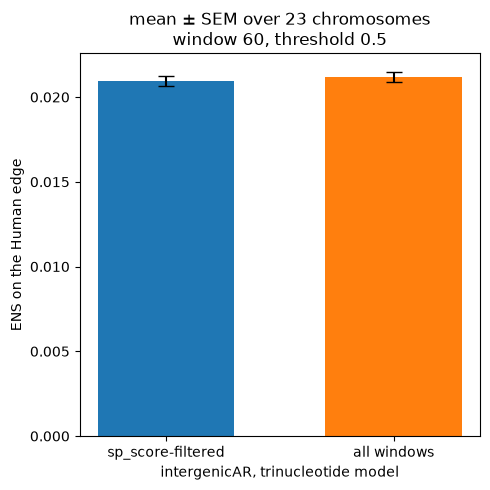

In [ ]:
labels = ["sp_score-filtered", "all windows"]
means = [stats.loc["ENS_quality", "mean"], stats.loc["ENS_all", "mean"]]
sems = [stats.loc["ENS_quality", "sem"], stats.loc["ENS_all", "sem"]]

fig, ax = plt.subplots(figsize=(5, 5))
ax.bar(labels, means, yerr=sems, capsize=6, width=0.6, color=["#1f77b4", "#ff7f0e"])
ax.set_ylabel("ENS on the Human edge")
ax.set_xlabel("intergenicAR, trinucleotide model")
ax.set_title(f"mean ± SEM over {len(df)} chromosomes\nwindow {WINDOW}, threshold {THRESHOLD}")
plt.tight_layout()
fig.savefig(FIGURES / f"ens_igar_quality_vs_all_{LABEL}.png", dpi=150)
plt.show()

The error bars are the SEM of the ENS across chromosomes, so they measure the spread between
chromosomes (X is well below every autosome), not the precision of either fit. The paired
per-chromosome change is `ENS_ratio` in the tables above.